## Statistical Analysis of Concrete Compressive Strength

### 1. Research Objective
本プロジェクトでは、Pythonを用いて、コンクリートの材料配合条件および養生期間と圧縮強度の関係を統計的に分析する。

### 2. Dataset Description
   #### 資料說明

In [44]:
import pandas as pd
import numpy as np

df = pd.read_csv("concrete_data.csv")
df.head()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [45]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   cement                         1030 non-null   float64
 1   blast_furnace_slag             1030 non-null   float64
 2   fly_ash                        1030 non-null   float64
 3   water                          1030 non-null   float64
 4   superplasticizer               1030 non-null   float64
 5   coarse_aggregate               1030 non-null   float64
 6   fine_aggregate                 1030 non-null   float64
 7   age                            1030 non-null   int64  
 8   concrete_compressive_strength  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


本データセットには欠損値が存在しないことを確認した。

In [3]:
df.describe()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


記述統計量を確認した結果、`blast_furnace_slag`（高炉スラグ）、`fly_ash`（フライアッシュ）、`superplasticizer`（高性能減水剤）の3変数について、最小値が0であることが確認された。
これらのゼロ値がデータの欠損を示すものか、材料が使用されていないことを示すものかを検討するため、次に各変数のゼロ値の件数を集計する。

### 3. Data Quality Assessment
   #### 3.1 Zero Values

In [4]:
print(f"Number of Zero Values in Each Column:")
print((df == 0).sum(axis = 0))

Number of Zero Values in Each Column:
cement                             0
blast_furnace_slag               471
fly_ash                          566
water                              0
superplasticizer                 379
coarse_aggregate                   0
fine_aggregate                     0
age                                0
concrete_compressive_strength      0
dtype: int64


データを確認したところ、以下の3つの変数に多数のゼロ値が含まれていた。<br>
blast_furnace_slag（高炉スラグ）：471件<br>
fly_ash（フライアッシュ）：566件<br>
superplasticizer（高性能減水剤）：379件<br>
これらの変数は、コンクリートの材料配合量を表している。そのため、値が0であることは、該当する材料が配合されていないことを意味すると考えられ、必ずしも欠損値を示すものではない。<br>
これらのゼロ値を欠損値（NaN）として扱い、削除してしまうと、特定の材料を使用していない配合条件のデータが分析対象から除外され、解析結果に偏りが生じる可能性がある。
したがって、本分析では、これらのゼロ値を有効な測定データとして扱い、削除せずに保持することとした。

 #### 3.2 Duplicate Records

In [5]:
duplicates_all = df.loc[df.duplicated(keep=False)]
print("Number of rows in duplicate groups:", len(duplicates_all))
duplicates_all

Number of rows in duplicate groups: 36


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
72,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.40
77,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.40
80,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.40
83,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
95,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.20
100,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.20
103,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.20


#### 3.3 重複データの特徴と取り扱い

全1,030件のデータを確認したところ、完全に一致する重複行が25件検出された。
重複データの内容を詳しく確認したところ、主に以下の2種類の材料配合条件に集中していることが分かった。

#### ① 配合条件 A

| 材料                 | 配合量（kg/m³） |
| ------------------ | ---------: |
| cement             |      425.0 |
| blast_furnace_slag |      106.3 |
| fly_ash            |        0.0 |
| water              |      153.5 |
| superplasticizer   |       16.5 |
| coarse_aggregate   |      852.1 |
| fine_aggregate     |      887.1 |

この配合条件では、以下の養生期間において、圧縮強度の測定値が完全に一致するレコードが複数存在していた。

| 養生期間（日） | 圧縮強度（MPa） | 同一レコード数 |
| :------:| :--------: | :------: |
|       3 |     33.40 |       3 |
|       7 |     49.20 |       3 |
|      28 |     60.29 |       3 |
|      56 |     64.30 |       3 |
|      91 |     65.20 |       3 |

#### ② 配合条件 B

| 材料                 | 配合量（kg/m³） |
| ------------------ | ---------: |
| cement             |      362.6 |
| blast_furnace_slag |      189.0 |
| fly_ash            |        0.0 |
| water              |      164.9 |
| superplasticizer   |       11.6 |
| coarse_aggregate   |      944.7 |
| fine_aggregate     |      755.8 |

この配合条件についても、複数の養生期間において、同一の測定値を持つレコードが確認された。

| 養生期間（日） | 圧縮強度（MPa） | 同一レコード数 |
| :------: | :--------: | :------: |
|       3 |     35.30 |       4 |
|       7 |     55.90 |       3 |
|      28 |     71.30 |       4 |
|      56 |     77.30 |       4 |
|      91 |     79.30 |       4 |

#### ③ その他の重複データ

上記2種類の配合条件以外にも、以下の重複データが確認された。

* データインデックス：801、809
* 養生期間：28日
* 圧縮強度：19.69 MPa
* 同一レコード数：2件

#### 3.4 重複データの考察

重複データには、以下の2つの特徴が認められた。

**① 同一の材料配合条件について、異なる養生期間で測定が行われている。**

これは、養生期間による圧縮強度の変化を確認するコンクリート強度試験において、一般的に考えられる実験方法と整合している。

**② 材料配合条件だけでなく、圧縮強度の測定値も完全に一致している。**

例えば、配合条件Bでは、養生期間28日の圧縮強度が71.30 MPaとなるレコードが4件存在していた。

このような重複は、データ整理時の重複登録による可能性がある一方、異なる試験で得られた測定値が、記録されている数値精度の範囲で一致した可能性も考えられる。

しかし、本データセットには個々の実験を識別するための試験番号などが含まれていないため、これらが独立した測定結果であるかどうかを判断することは困難である。

#### 3.5 重複データが解析結果に与える可能性のある影響

仮に重複データが意図しない重複登録であった場合、そのまま解析に使用することで、以下のような影響が生じる可能性がある。

* 特定の材料配合条件が過大に重み付けされる。
* 回帰係数の推定結果が変化する。
* 標準誤差やp値の推定に影響する。
* 決定係数（R²）やRMSEなどのモデル評価指標が変化する。

一方、これらが独立した実験結果である場合、重複行を機械的に削除することも適切ではない。

そのため、本分析では重複行を直ちに削除せず、全1,030件を用いた解析を基本とした。

さらに、重複データの取り扱いが解析結果に与える影響を確認するため、重複行を除外した場合との感度分析を実施することとした。


### 4. Exploratory Data Analysis（探索的データ解析）
   #### 4.1 Distribution Analysis（分布の確認）

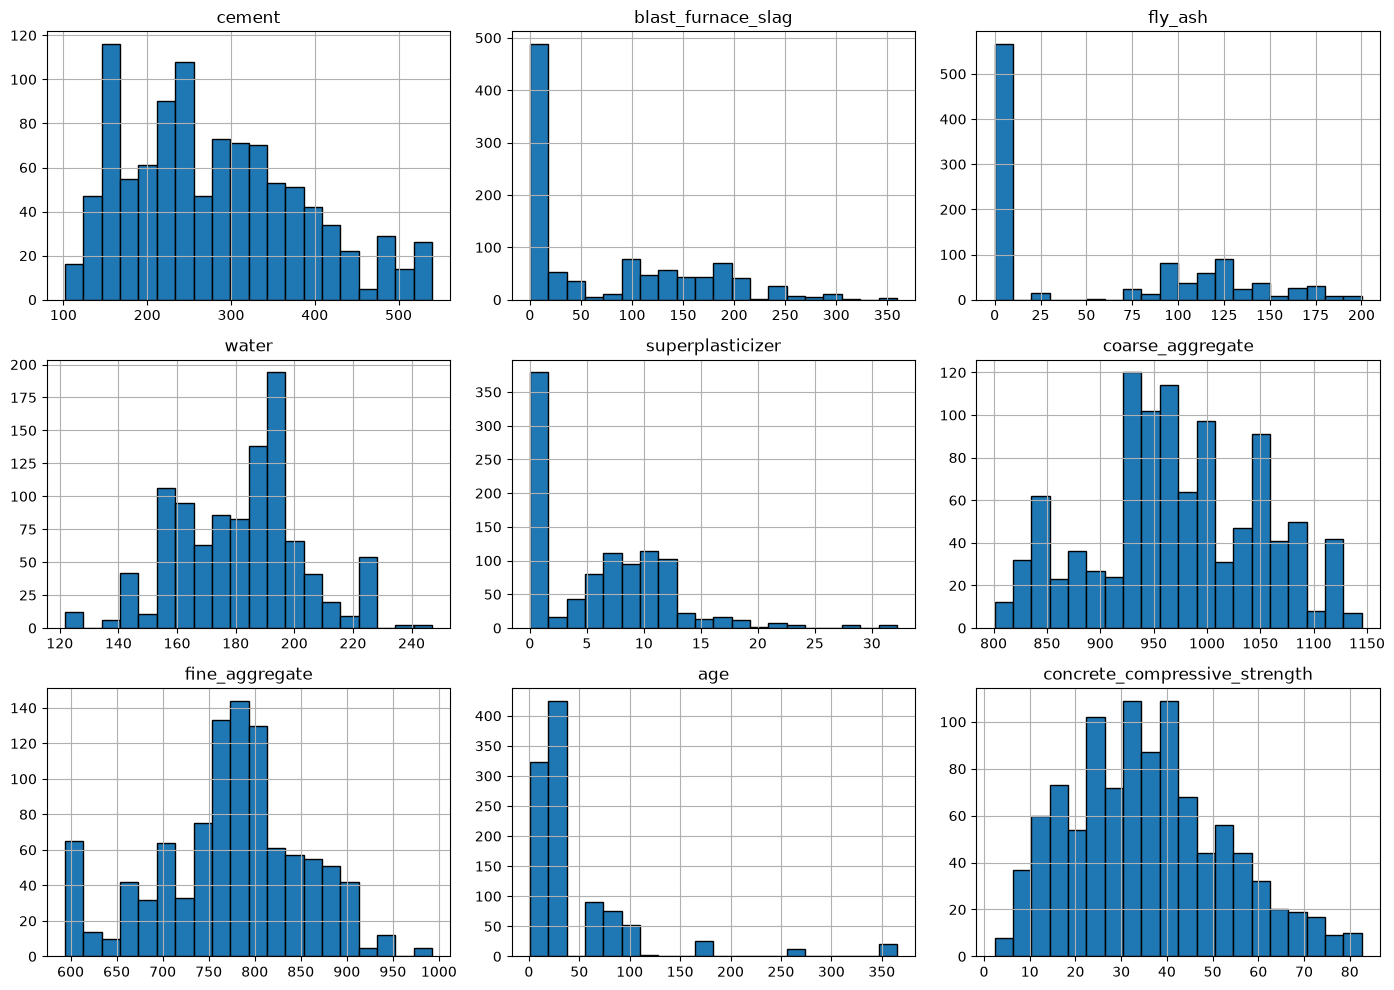

In [6]:
from matplotlib import pyplot as plt

original_cols = [
    "cement",
    "blast_furnace_slag",
    "fly_ash",
    "water",
    "superplasticizer",
    "coarse_aggregate",
    "fine_aggregate",
    "age",
    "concrete_compressive_strength"
]

df[original_cols].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)

plt.tight_layout()
plt.show()

In [7]:
print(f"圧縮強度の分布歪度:",df["concrete_compressive_strength"].skew())

圧縮強度の分布歪度: 0.416977288410718


圧縮強度の分布をヒストグラムで確認したところ、データは主に20～45 MPa付近に集中しており、高強度側にやや長い裾を持つ分布が観察された。<br>
記述統計量を確認すると、平均値は35.82 MPa、中央値は34.45 MPaであり、平均値が中央値をわずかに上回っていた。<br>
さらに、歪度（Skewness）を算出した結果、0.417となり、分布が軽度の右偏（正の歪み）を示していることが確認された。<br>
ただし、歪度の絶対値は比較的小さく、著しく非対称な分布ではないと考えられる。

養生期間（Age）の分布をヒストグラムで確認したところ、データは比較的短い養生期間に集中しており、長期間側に裾が伸びる明らかな右偏（正の歪み）が認められた。
記述統計量を確認すると、平均値は45.66日、中央値は28日であり、平均値が中央値を大きく上回っていた。また、最小値は1日、最大値は365日であり、養生期間には大きなばらつきが見られた。
さらに、第1四分位数は7日、第3四分位数は56日であり、全データの約50%が7～56日の範囲に含まれていた。
以上の結果から、養生期間の分布は左右対称ではなく、少数の長期養生データによって右側に裾が伸びていることが分かった。
そこで、後続の分析では、養生期間に自然対数変換を適用し、変換前後の分布を比較することとした。

#### 4.2 Log Transformation of Age（養生期間の対数変換）

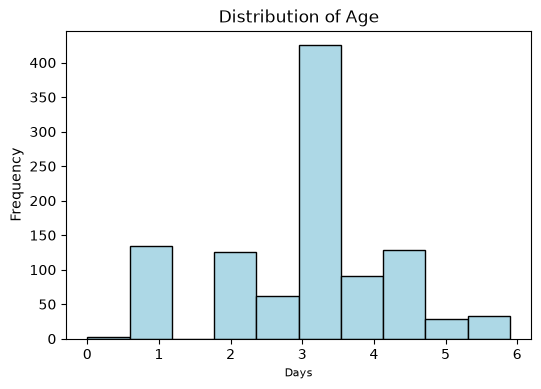

<Figure size 640x480 with 0 Axes>

In [8]:
df["log_age"] = np.log(df["age"])

plt.figure(figsize=(6,4))
plt.hist(df["log_age"],  
         color = "lightblue", 
         edgecolor='black'
        )
plt.title("Distribution of Age")
plt.xlabel("Days", fontsize=8)
plt.ylabel("Frequency")
plt.show()
plt.clf()

#### 養生期間の対数変換と分布の比較
変換後のヒストグラムでは、分布のピークが中央付近に位置し、変換前と比較して左右の非対称性が緩和され、より対称的な分布に近づいていることが視覚的に確認された。<br>
なお、説明変数が正規分布に従うことは、線形回帰分析の必須条件ではない。そのため、本分析における対数変換は、正規性を満たすことを目的としたものではない。<br>
後続の相関分析では、元の養生期間と対数変換後の養生期間について、それぞれ圧縮強度との関係を比較し、回帰モデルへの適用を検討する。

#### 4.4 Relationships with Strength
各説明変数と目的変数であるコンクリート圧縮強度（Compressive Strength）との関係を把握するため、散布図を作成した。

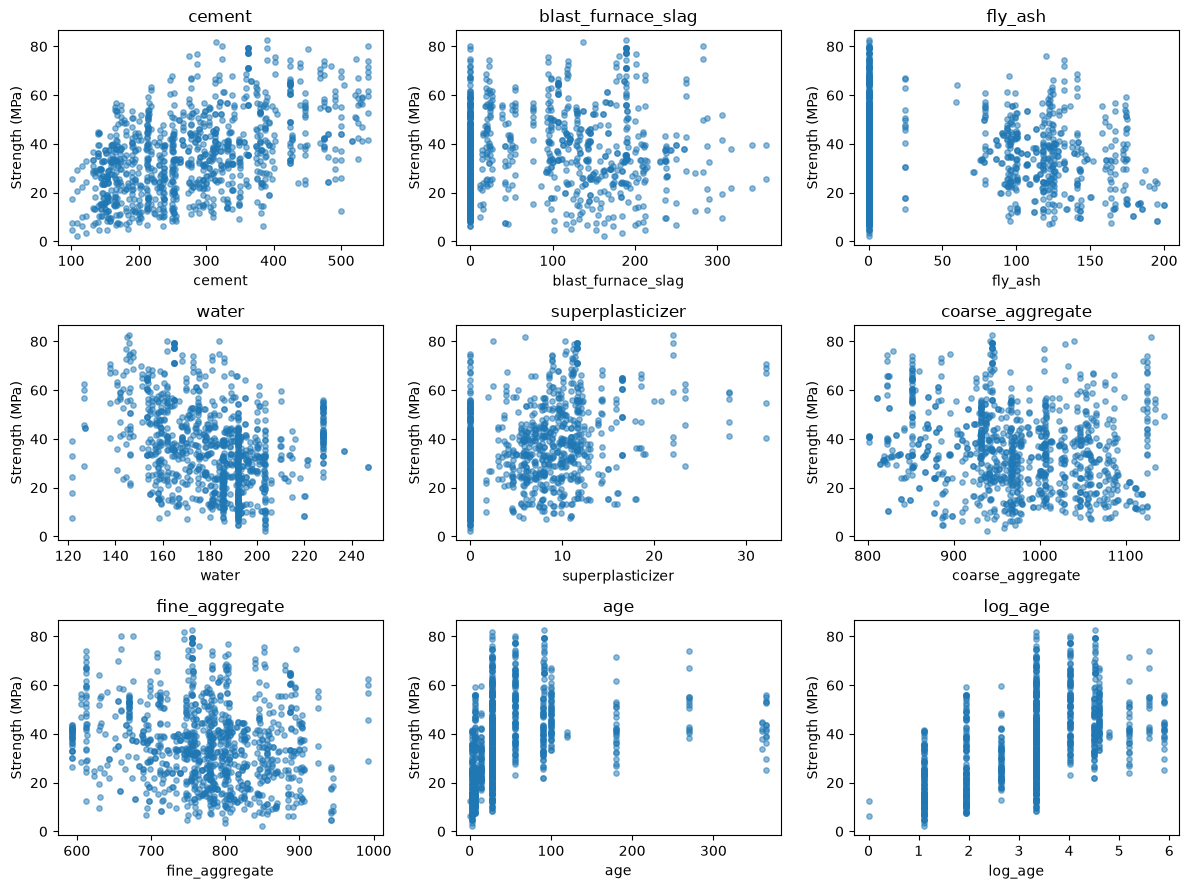

In [9]:
features = [
    "cement",
    "blast_furnace_slag",
    "fly_ash",
    "water",
    "superplasticizer",
    "coarse_aggregate",
    "fine_aggregate",
    "age",
    "log_age"
]

fig, axes = plt.subplots(
    3, 3,
    figsize=(12, 9)
)

for ax, col in zip(axes.flat, features):
    ax.scatter(
        df[col],
        df["concrete_compressive_strength"],
        alpha=0.5,
        s=15
    )

    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Strength (MPa)")

plt.tight_layout()
plt.show()

散布図を確認したところ、cement（セメント使用量）では、使用量の増加に伴い圧縮強度が高くなる傾向が見られた。<br>
また、age（養生期間）についても、養生期間が長くなるほど圧縮強度が高くなる傾向が認められたが、その関係は必ずしも直線的ではなかった。
そこで、後続の分析では、cement と圧縮強度の関係に加え、対数変換前の age および変換後の log_age と圧縮強度の関係に着目し、散布図と相関係数を用いて詳しく検討する。

### 5. Correlation Analysis（相関分析）
#### 5.1 Cement vs. Compressive Strength

In [10]:
import scipy.stats as stats

r,p = stats.pearsonr(df["cement"], df["concrete_compressive_strength"])
print(r)
print(f"P-value:",p)

0.49783191932415743
P-value: 1.324183307226925e-65


セメント量と圧縮強度の間には、中程度の正の相関が認められた（r = 0.498）。

####  5.2 Age vs. Compressive Strength

In [11]:
import scipy.stats as stats

r,p = stats.pearsonr(df["age"], df["concrete_compressive_strength"])
print(r)
print(f"P-value:",p)

0.3288730007799874
P-value: 2.106340553631996e-27


 #### 5.3 log(Age) vs. Compressive Strength

In [12]:
r,p = stats.pearsonr(df["log_age"], df["concrete_compressive_strength"])
print(f"The correalation of log_age and concrete_compressive_strength:",r)
print(f"P-value:",p)

The correalation of log_age and concrete_compressive_strength: 0.5521803859561103
P-value: 2.911296350747831e-83


養生期間（Age）と圧縮強度の関係についてPearsonの相関係数を算出したところ、r = 0.329であり、正の相関が確認された。
散布図から非線形な関係が示唆されたため、養生期間を自然対数変換したうえで再度相関分析を行った。その結果、相関係数はr = 0.552に上昇し、単回帰モデルの決定係数も0.108から0.305に改善した。
以上より、養生期間を対数変換することで、圧縮強度との関係をより適切に記述できる可能性が示された。ただし、材料配合条件などの影響を考慮した追加分析が必要である。

### 6. Multicollinearity Assessment
#### 6.1 Correlation Matrix 
説明変数間の相関関係を確認するため、Pearsonの相関係数を算出し、ヒートマップを作成した。

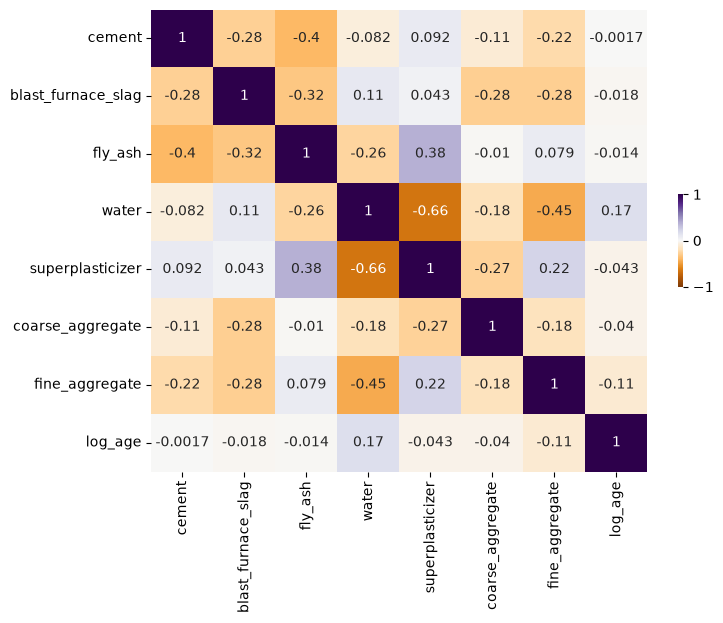

In [13]:
import seaborn as sns

log_df = df.drop(columns=["age","concrete_compressive_strength"])

plt.figure(figsize=(8,6))

corr_grid = log_df.corr()
sns.heatmap(corr_grid,
            xticklabels=corr_grid.columns, 
            yticklabels=corr_grid.columns, 
            vmin=-1, center=0, 
            vmax=1, cmap='PuOr', 
            annot=True, cbar_kws={'shrink': .2})

plt.show()

その結果、以下の変数の組み合わせに比較的強い負の相関が認められた。

| 変数の組み合わせ                     | 相関係数（r） | 相関の程度     |
| ---------------------------- | ------: | --------- |
| `water` × `superplasticizer` |   -0.66 | 比較的強い負の相関 |
| `water` × `fine_aggregate`   |   -0.45 | 中程度の負の相関  |
| `cement` × `fly_ash`         |   -0.40 | 中程度の負の相関  |

特に、`water`（水の使用量）と `superplasticizer`（高性能減水剤の使用量）の間には、比較的強い負の相関（r = -0.66）が認められた。
これは、本データセットにおいて、**高性能減水剤の使用量が多い配合ほど、水の使用量が少ない傾向にある**ことを示している。
この傾向は、高性能減水剤がコンクリートの流動性を維持しながら必要な水量を低減する目的で使用されるという、材料工学上の知見とも整合している。<br>
ただし、相関関係は因果関係を示すものではないため、高性能減水剤の使用量の増加が水の使用量の減少を直接引き起こしたと結論づけることはできない。
また、説明変数間の個々の相関係数がそれほど高くない場合でも、複数の説明変数の線形結合によって多重共線性が生じる可能性がある。
そこで、次のステップでは、**分散拡大係数（Variance Inflation Factor：VIF）** を算出し、多重共線性の程度を定量的に評価する。

#### 6.2 Variance Inflation Factor (VIF)
VIFによる多重共線性の評価<br>
説明変数間の多重共線性を評価するため、分散拡大係数（Variance Inflation Factor：VIF）を算出した。

In [14]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

log_df_const = sm.add_constant(log_df)

vif_df = pd.DataFrame({
    "Feature": log_df.columns,
    "VIF": [
        variance_inflation_factor(log_df_const.values, i)
        for i in range(1,log_df_const.shape[1])
    ]
})

vif_df

,Feature,VIF
0,cement,7.532370
1,blast_furnace_slag,7.279188
2,fly_ash,6.141118
3,water,6.983870
4,superplasticizer,2.980300
5,coarse_aggregate,5.088962
6,fine_aggregate,7.030352
7,log_age,1.052302


一般的に、VIFが5を超える場合は多重共線性に注意が必要とされ、10を超える場合はより深刻な多重共線性が疑われる。ただし、これらはあくまで経験的な判断基準である。
今回の計算結果では、以下の6変数でVIFが5を超えていた。
|説明変数|	VIF|
|:------|------|
|cement	|7.54|
|blast_furnace_slag	|7.29|
|fly_ash	|6.17|
|water	|7.01|
|coarse_aggregate	|5.09|
|fine_aggregate	|7.03|

特に、cement、blast_furnace_slag、water、fine_aggregate のVIFは約7であり、他の説明変数との間に一定程度の多重共線性が存在することが示唆された。
一方、すべての変数のVIFは10未満であり、極端に高い値は認められなかった。<br>
コンクリートの材料配合では、各材料の使用量が相互に関連しているため、このような多重共線性が生じることは十分に考えられる。多重共線性が存在すると、回帰係数の標準誤差が大きくなり、各説明変数の効果を個別に推定する際の精度が低下する可能性がある。<br>
ただし、VIFが5を超えているという理由だけで、材料工学上重要な説明変数を機械的に除外することは適切ではない。

### 7. Multiple Linear Regression
#### 7.1 Model Construction

In [39]:
y = df["concrete_compressive_strength"]
X = log_df_const

model = sm.OLS(y, X).fit()

#### 7.2 Regression Results

In [40]:
print(model.summary())

                                  OLS Regression Results                                 
Dep. Variable:     concrete_compressive_strength   R-squared:                       0.819
Model:                                       OLS   Adj. R-squared:                  0.817
Method:                            Least Squares   F-statistic:                     575.6
Date:                           Mon, 09 Nov 2026   Prob (F-statistic):               0.00
Time:                                   15:10:35   Log-Likelihood:                -3482.4
No. Observations:                           1030   AIC:                             6983.
Df Residuals:                               1021   BIC:                             7027.
Df Model:                                      8                                         
Covariance Type:                       nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
-------------

### 8. Model Diagnostics
#### 8.1 Residual Analysis(残差と予測値の散布図)

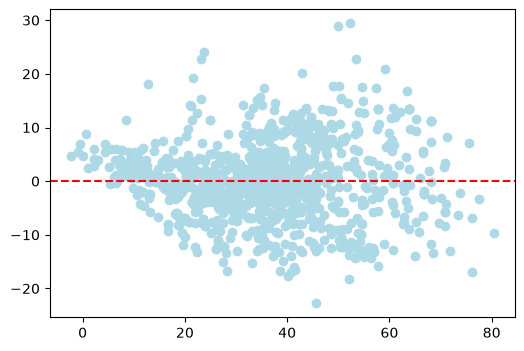

In [17]:
fitted = model.fittedvalues
residuals = model.resid

fig, ax = plt.subplots(figsize=(6, 4))

ax.scatter(fitted, residuals,color="lightblue" )
ax.axhline(y=0, color="red", linestyle="--")

plt.show()

残差と予測値の関係を散布図で確認したところ、予測値が小さい領域では残差が正の方向に偏る傾向が見られた。一方、予測値が中程度の領域では、残差が0を中心として正負両方向に分布していた。また、予測値の大きさによって残差のばらつきが異なるように見受けられた。<br>
これらの結果から、残差の分散が一定ではない可能性があり、異分散性（Heteroscedasticity）の存在が疑われる。そこで、後続の分析では、Breusch–Pagan検定を実施し、異分散性の有無を統計的に検討する。

#### 8.2 Normal Q-Q Plot（残差の正規性の確認）
回帰モデルの残差が正規分布に従うかを視覚的に確認するため、Normal Q–Q Plotを作成した。

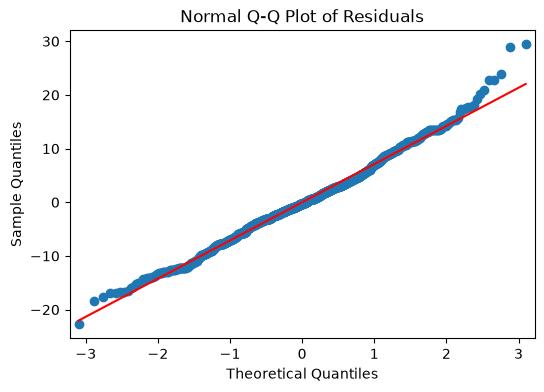

In [18]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
sm.qqplot(
    residuals,
    line="s",
    ax=ax
)
ax.set_title("Normal Q-Q Plot of Residuals")

plt.show()

Q–Q Plotを確認したところ、分布の中央部分では、多くの点が基準線に沿って分布しており、正規分布におおむね近い傾向が認められた。一方、分布の両端では基準線からのずれが見られ、特に右側の上位分位点では、観測値が基準線を大きく上回っていた。<br>
このことから、残差の分布は中央部分では正規分布に比較的近いものの、裾の部分では正規分布から逸脱しており、正規性が完全には満たされていない可能性が示唆された。
したがって、回帰係数の統計的推論を行う際には、残差の非正規性に注意する必要がある。

In [31]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp_test = het_breuschpagan(
    model.resid,
    X
)

bp_df = pd.DataFrame({
    "Statistic": [
        "LM Statistic",
        "LM p-value",
        "F Statistic",
        "F p-value"
    ],
    "Value": bp_test
})

bp_df

,Statistic,Value
0,LM Statistic,1.018375e+02
1,LM p-value,1.797095e-18
2,F Statistic,1.400295e+01
3,F p-value,1.897593e-19


Breusch–Pagan検定の結果、帰無仮説（誤差項の分散が一定である）を棄却する結果が得られ、現在の回帰モデルには異分散性（Heteroscedasticity）が存在することを示唆する統計的証拠が認められた。

これは、誤差項の分散が説明変数の値によって変化し、一定ではない可能性があることを意味する。

異分散性は、回帰分析における以下の項目に影響を及ぼす可能性がある。

項目	異分散性による影響
回帰係数（Coefficient）	外生性などの条件が満たされていれば、OLS推定量の不偏性や一致性は維持されるが、推定効率が低下する可能性がある。
決定係数（R²）	異分散性だけを理由にR²の計算が無効になるわけではない。ただし、R²から標準誤差や統計的推論の信頼性を判断することはできない。
標準誤差（Standard Error）	通常のOLS標準誤差が適切に推定されず、過大評価または過小評価される可能性がある。
t統計量（t-statistic）	標準誤差の推定が不適切な場合、t統計量にも影響が生じる可能性がある。
p値（p-value）	通常のOLSに基づく有意性検定の結果が信頼できなくなる可能性がある。
95%信頼区間（95% Confidence Interval）	通常の標準誤差に基づく信頼区間が過度に狭く、または広くなり、実際の被覆確率が名目上の95%から乖離する可能性がある。

以上より、異分散性が存在しても、必ずしも回帰係数の推定値そのものに偏りが生じるわけではないが、標準誤差やp値などの統計的推論の信頼性に影響する可能性がある。

そこで、本分析では、異分散性の影響を考慮するため、HC3ロバスト標準誤差（Heteroscedasticity-Consistent Standard Errors） を用いて回帰係数の統計的有意性を再評価する。

#### 8.4 HC3 Robust Standard Errors

In [22]:
robust_model = model.get_robustcov_results(
    cov_type="HC3"
)
print(robust_model.summary())

                                  OLS Regression Results                                 
Dep. Variable:     concrete_compressive_strength   R-squared:                       0.819
Model:                                       OLS   Adj. R-squared:                  0.817
Method:                            Least Squares   F-statistic:                     566.1
Date:                           Mon, 09 Nov 2026   Prob (F-statistic):               0.00
Time:                                   14:23:36   Log-Likelihood:                -3482.4
No. Observations:                           1030   AIC:                             6983.
Df Residuals:                               1021   BIC:                             7027.
Df Model:                                      8                                         
Covariance Type:                             HC3                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
-------------

In [23]:
comparison = pd.DataFrame({
    "Feature": model.model.exog_names,
    "Coefficient": model.params.values,
    "OLS_SE": model.bse.values,
    "HC3_SE": robust_model.bse,
    "OLS_p": model.pvalues.values,
    "HC3_p": robust_model.pvalues
})

comparison

,Feature,Coefficient,OLS_SE,HC3_SE,OLS_p,HC3_p
0,const,-77.533388,18.330800,22.454848,2.550382e-05,5.774327e-04
1,cement,0.134857,0.005849,0.006819,5.121581e-95,5.950791e-74
2,blast_furnace_slag,0.115945,0.006965,0.008648,3.099533e-55,7.193031e-38
3,fly_ash,0.094391,0.008625,0.009528,1.950061e-26,3.736010e-22
4,water,-0.128817,0.027564,0.034884,3.359978e-06,2.335979e-04
5,superplasticizer,0.118822,0.064366,0.077040,6.517613e-02,1.232981e-01
6,coarse_aggregate,0.029681,0.006462,0.007823,4.912984e-06,1.570142e-04
7,fine_aggregate,0.035989,0.007366,0.008824,1.194949e-06,4.881471e-05
8,log_age,8.746595,0.191768,0.195395,1.438418e-248,5.003595e-243


In [ ]:
### 8.4 HC3ロバスト標準誤差による回帰結果の評価

Breusch–Pagan検定の結果、残差に異分散性が存在することが示唆されたため、HC3ロバスト標準誤差を用いて回帰係数の統計的有意性を再評価した。

通常のOLS標準誤差とHC3ロバスト標準誤差を比較したところ、すべての変数においてHC3標準誤差の方が大きくなった。

特に、`water`、`superplasticizer` などの変数では、標準誤差の増加に伴い、p値も大きくなっていた。

一方、HC3ロバスト標準誤差を適用しても、回帰係数の推定値そのものは変化しなかった。

#### 統計的有意性の評価

HC3ロバスト標準誤差に基づくp値を確認した結果、以下の7変数は5%有意水準で統計的に有意であった。

* `cement`
* `blast_furnace_slag`
* `fly_ash`
* `water`
* `coarse_aggregate`
* `fine_aggregate`
* `log_age`

一方、`superplasticizer` のp値は、通常のOLSでは0.065、HC3では0.123となり、いずれも5%有意水準を上回った。

したがって、本モデルでは、他の説明変数を一定とした場合の `superplasticizer` の回帰係数について、5%有意水準で0と異なると判断するための十分な統計的証拠は得られなかった。

#### 考察

今回の結果では、HC3ロバスト標準誤差を適用することで標準誤差が全体的に増加したものの、5%有意水準における各説明変数の有意性の判定は変化しなかった。

このことから、本モデルの主要な統計的結論は、通常のOLS標準誤差とHC3ロバスト標準誤差の選択に対して、一定の頑健性を示していると考えられる。

ただし、HC3ロバスト標準誤差は異分散性に対応した標準誤差の推定方法であり、多重共線性やモデルの非線形性、観測値間の依存性などを解消するものではない。

したがって、回帰係数の解釈に際しては、これらのモデル上の制約にも注意する必要がある。

結論:「異分散性を考慮した場合でも、主要な回帰係数の統計的有意性に関する結論は維持された。」

#### 8.5 Actual vs. Predicted
回帰モデルの当てはまりを視覚的に評価するため、圧縮強度の実測値と予測値の散布図を作成した。

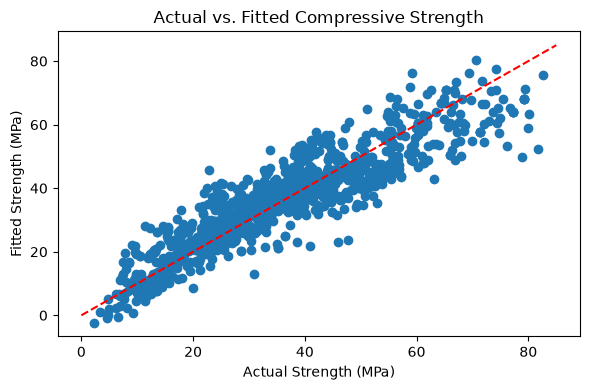

In [43]:
fig, ax = plt.subplots(figsize=(6, 4))

ax.scatter(df["concrete_compressive_strength"],fitted)
ax.plot([0, 85], [0, 85], "r--")

ax.set_xlabel("Actual Strength (MPa)")
ax.set_ylabel("Fitted Strength (MPa)")
ax.set_title("Actual vs. Fitted Compressive Strength")

plt.tight_layout()
plt.show()

図中の赤い破線は、実測値と予測値が完全に一致する場合を示す基準線（y = x）である。

散布図を確認したところ、多くの観測値が基準線の周辺に分布しており、モデルは圧縮強度の変動をある程度捉えていることが確認された。

一方、圧縮強度が低い領域では予測値が実測値を上回る傾向が見られ、高強度の領域では予測値が実測値を下回る傾向が観察された。

このことから、本モデルには低強度側での過大推定、および高強度側での過小推定が生じる可能性が示唆された。

なお、本図はモデルの構築に使用したデータに対する予測結果を示しており、未知のデータに対する予測精度を保証するものではない。

したがって、本結果はモデルの標本内での当てはまりを評価するものとして解釈する必要がある。

In [ ]:
import numpy as np

rmse = np.sqrt(np.mean((y - fitted) ** 2))

print(f"Training RMSE: {rmse:.3f} MPa")

### モデル診断のまとめ

残差分析および実測値と予測値の比較から、本モデルは圧縮強度の変動を一定程度説明できる一方、異分散性や一部の強度領域における系統的な予測誤差など、いくつかの課題が確認された。

異分散性については、HC3ロバスト標準誤差を適用した結果、通常のOLS標準誤差と比較して、各説明変数の統計的有意性の判定に変化は認められなかった。

この結果から、主要な統計的結論は、標準誤差の推定方法に対して一定の頑健性を有していることが示唆された。

一方、データ品質の確認では、完全に一致する重複行が25件存在することが明らかになっている。

これらの重複行が独立した実験結果であるかどうかは判断できないため、その取り扱いが回帰分析の結果に影響を与える可能性がある。

そこで、次の章では、重複行を保持した場合と除外した場合の回帰分析結果を比較し、**データ処理方法に対する分析結果の頑健性を感度分析によって評価する。**


### 9. Sensitivity Analysis（感度分析）
#### 9.1 解析目的<br>
本分析では、完全重複行の取り扱いが回帰分析の結果に与える影響を検討する。

具体的には、以下の2つのデータセットを用いて、同一の説明変数による重回帰分析を実施する。

| モデル     | データの取り扱い | サンプル数 |
| ------- | -------- | ----: |
| Model A | 重複行を保持   | 1,030 |
| Model B | 完全重複行を除外 | 1,005 |

両モデルについて、決定係数（R²）、自由度調整済み決定係数、回帰係数、およびHC3ロバスト標準誤差に基づくp値を比較する。

これにより、重複行の取り扱いによって主要な統計的結論がどの程度変化するかを確認する。

なお、本分析は重複行の削除が適切であることを証明するものではなく、データ処理上の判断に対する解析結果の感度を評価することを目的とする。


In [41]:
df_unique = df.drop_duplicates().copy()

X_unique = df_unique[features].drop(columns="age")
y_unique = df_unique["concrete_compressive_strength"]

X_unique_const = sm.add_constant(X_unique)

model_unique = sm.OLS(
    y_unique,
    X_unique_const
).fit()

print(model_unique.summary())

                                  OLS Regression Results                                 
Dep. Variable:     concrete_compressive_strength   R-squared:                       0.812
Model:                                       OLS   Adj. R-squared:                  0.810
Method:                            Least Squares   F-statistic:                     536.6
Date:                           Mon, 09 Nov 2026   Prob (F-statistic):               0.00
Time:                                   15:12:57   Log-Likelihood:                -3390.7
No. Observations:                           1005   AIC:                             6799.
Df Residuals:                                996   BIC:                             6844.
Df Model:                                      8                                         
Covariance Type:                       nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
-------------

In [ ]:
9.2 Comparison of Regression Results

本分析では、以下の2つのモデルを比較した。<br>

|モデル	|データの取り扱い	|サンプル数|
|-------|-----|----------|
|Model A	|全データを使用（重複行を保持）	|1,030|
|Model B	|完全重複行を除外	|1,005|

両モデルに同一の説明変数と回帰分析手法を適用し、以下の指標を比較した。

決定係数（R²）
自由度調整済み決定係数（Adjusted R²）
回帰係数
HC3ロバスト標準誤差に基づくp値
#### 9.2 決定係数の比較
|指標	|Model A|	Model B|
|-------|-----|----------|
|サンプル数|	1,030	|1,005|
|R²|	0.8185	|0.8117|
|Adjusted R²|	0.8171	|0.8102|

重複行を除外した結果、R²は0.8185から0.8117へと低下した。その差は約0.0068であり、モデル全体の当てはまりに大きな変化は認められなかった。

ただし、両モデルでは解析対象のデータ数が異なるため、R²のみを用いてモデルの優劣を判断することは適切ではない。

#### 9.3 回帰係数の比較
|説明変数|Model A|Model B|変化率|
|-------|-----|-------|------|
|cement	|0.135	|0.132	|-2.06%
|blast_furnace_slag	|0.116	|0.111	|-3.85%|
|fly_ash	|0.094	|0.092	|-2.44%|
|water	|-0.129	|-0.132	|-2.50%|
|superplasticizer	|0.119	|0.112	|-5.62%|
|coarse_aggregate	|0.030	|0.027	|-8.07%|
|fine_aggregate	|0.036	|0.034	|-5.60%|
|log_age	|8.747	|8.662	|-0.96%|

すべての説明変数において、回帰係数の符号は維持された。

相対変化率が最も大きかった変数は coarse_aggregate であり、約8.1%の変化が認められた。

一方、log_age の変化率は約1.0%であり、比較的安定した推定結果が得られた。

#### 9.4 HC3ロバスト標準誤差による有意性の比較

異分散性の影響を考慮するため、両モデルについてHC3ロバスト標準誤差を用いた統計的推論を行った。

その結果、両モデルともに superplasticizer を除く7つの説明変数が5%水準で統計的に有意であった。

superplasticizer のp値は、Model Aでは0.123、Model Bでは0.145となり、いずれも5%水準では統計的に有意ではなかった。

したがって、重複行の除外によって、各説明変数の統計的有意性の判定に変化は認められなかった。

#### 9.5 考察

以上の結果から、完全重複行25件を除外しても、モデル全体の当てはまり、回帰係数の符号、および統計的有意性の判定に大きな変化は認められなかった。

このことから、本分析の主要な結果は、重複行の取り扱いに対して一定の頑健性を有していると考えられる。

ただし、今回の感度分析は重複行を除外した場合の結果を比較したものであり、重複行の削除が適切であることを証明するものではない。

また、観測値の独立性を確認できる情報が不足しているため、統計的推論の解釈には注意が必要である。